In [1]:
from collections import defaultdict
from pathlib import Path

import pandas as pd
from acteval.plot.frequency import plot_agg_acts
from matplotlib import pyplot as plt
from matplotlib.patches import Patch

In [2]:
cmap = {
    "home": (0.5529411764705883, 0.8274509803921568, 0.7803921568627451),
    "other": (1.0, 1.0, 0.7019607843137254),
    "shop": (0.7450980392156863, 0.7294117647058823, 0.8549019607843137),
    "work": (0.984313725490196, 0.5019607843137255, 0.4470588235294118),
    "escort": (0.5019607843137255, 0.6941176470588235, 0.8274509803921568),
    "visit": (0.9921568627450981, 0.7058823529411765, 0.3843137254901961),
    "education": (0.7019607843137254, 0.8705882352941177, 0.4117647058823529),
    "medical": (0.9882352941176471, 0.803921568627451, 0.8980392156862745),
    "travel": (0.8509803921568627, 0.8509803921568627, 0.8509803921568627),
    "leisure": (0.996078431372549, 0.8509803921568627, 0.6509803921568628),
}


def latest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[-1]


def earliest(path: Path):
    versions = sorted(
        [
            d
            for d in path.iterdir()
            if d.is_dir() and d.name.startswith("version")
        ]
    )
    print(
        f"Found versions for {path.name}: {[v.name for v in versions]}. Returning {versions[-1]}"
    )
    return path.name, versions[0]


def iter_models(path: Path):
    for dir in path.iterdir():

        if dir.is_dir():

            yield latest(dir)


def find_nth(path: Path, n=0):

    ranks = (
        pd.read_csv(path / "domain_distances.csv")
        .drop(columns=["domain", "observed", "mean", "std"], errors="ignore")
        .rank(axis=1, method="min")
        .sum(axis=0)
    )
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def best_quality(path: Path, n=0):

    data = pd.read_csv(path / "domain_distances.csv")
    data = data[data.domain == "sample quality"].drop(
        columns=["domain", "observed", "mean", "std"], errors="ignore"
    )
    ranks = data.rank(axis=1, method="min").sum(axis=0)
    ranked = [i for _, i in sorted(zip(ranks, ranks.index))]
    top = ranked[n]
    dir = path / top
    yield latest(dir)


def load_attributes(path: Path, default=None):
    if (path / "synthetic_attributes.csv").exists():
        print(f"Loading synthetic attributes from {path}")
        return pd.read_csv(path / "synthetic_attributes.csv")
    if (path / "synthetic_labels.csv").exists():
        print(f"Loading synthetic labels from {path}")
        return pd.read_csv(path / "synthetic_labels.csv")
    print(f"Failed to find attributes at {path}")
    return default


def split_on(schedules, attributes, by="work_status"):
    splits = attributes.groupby(by)
    return {
        k: schedules.loc[schedules.pid.isin(list(v.pid))]
        for k, v in splits
        if k != "unknown"
    }


def styler(df, vmin=-1, vmax=1):
    df = -df
    df.loc["24", "london"] = None
    df.loc["00-24", "london"] = None
    for yrs in ["24"]:
        for source in ["west", "global"]:
            df.loc[yrs, source] = None

    styled = df.style.background_gradient(
        cmap="RdYlGn", vmin=vmin, vmax=vmax
    ).format("{:.1%}", na_rep="")

    return styled

In [3]:
training_data_route = Path("../../tmp/foundation/experiment")

target_schedules = pd.read_csv(training_data_route / "24_london_activities.csv")
target_attributes = pd.read_csv(
    training_data_route / "24_london_attributes.csv"
)

counts = defaultdict(list)
for yrs in ["24", "23-24", "20-24", "10-24", "00-24"]:
    for scope in ["london", "uk", "europe", "west", "global"]:
        training_data_route = Path(
            f"../../tmp/foundation/experiment/{yrs}_{scope}_attributes.csv"
        )
        atts = pd.read_csv(training_data_route, usecols=[0]).shape[0]
        counts[yrs].append(atts)

counts = pd.DataFrame(
    counts, index=["london", "uk", "europe", "west", "global"]
).T
counts

,london,uk,europe,west,global
24,18071,127618,188898,188898,197020
23-24,27432,228187,346089,346830,369337
20-24,43008,404368,691803,707112,882551
10-24,60520,1464216,1847895,2121429,2376675
00-24,60520,2543564,2927243,3583884,3839130


In [4]:
base = counts.iloc[0].iloc[0]
relative = (counts - base) / base
relative

,london,uk,europe,west,global
24,0.000000,6.062033,9.453102,9.453102,9.902551
23-24,0.518012,11.627248,18.151624,18.192629,19.438105
20-24,1.379946,21.376626,37.282497,38.129655,47.837972
10-24,2.349012,80.025732,101.257484,116.394112,130.518732
00-24,2.349012,139.753915,160.985668,197.322395,211.447015


In [5]:
styler(-relative, vmin=-200, vmax=200)

,london,uk,europe,west,global
24,,606.2%,945.3%,,
23-24,51.8%,1162.7%,1815.2%,1819.3%,1943.8%
20-24,138.0%,2137.7%,3728.2%,3813.0%,4783.8%
10-24,234.9%,8002.6%,10125.7%,11639.4%,13051.9%
00-24,,13975.4%,16098.6%,19732.2%,21144.7%


In [6]:
training_data_route = Path("../../tmp/foundation/experiment")

training_schedules = {}
training_attributes = {}

counts = defaultdict(list)
for yrs in ["24", "23-24"]:
    for scope in ["london", "uk", "europe", "west", "global"]:
        schedules_path = Path(
            f"../../tmp/foundation/experiment/{yrs}_{scope}_activities.csv"
        )
        attributes_path = Path(
            f"../../tmp/foundation/experiment/{yrs}_{scope}_attributes.csv"
        )
        training_schedules[f"{yrs}_{scope}"] = pd.read_csv(schedules_path)
        training_attributes[f"{yrs}_{scope}"] = pd.read_csv(attributes_path)

/tmp/ipykernel_1673864/245316418.py:16: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  training_attributes[f"{yrs}_{scope}"] = pd.read_csv(attributes_path)
/tmp/ipykernel_1673864/245316418.py:16: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  training_attributes[f"{yrs}_{scope}"] = pd.read_csv(attributes_path)
/tmp/ipykernel_1673864/245316418.py:16: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  training_attributes[f"{yrs}_{scope}"] = pd.read_csv(attributes_path)


In [7]:
def freq_plotter(all_schedules, schedules, attributes):
    act_order = all_schedules.act.value_counts().index.to_list()
    class_map = {n: i for i, n in enumerate(act_order)}
    class_map["medical"] = len(class_map)
    class_map["visit"] = len(class_map)  # add unknown class
    print(f"Class map: {class_map}")

    FILTER = ["student", "employed", "unemployed", "retired"]
    NAMES = ["Student", "Employed", "Unemployed", "Retired"]

    h = len(schedules)
    w = len(FILTER)
    fig, axes = plt.subplots(
        h, w + 2, figsize=(w * 2.2, h * 2), sharex=False, sharey=False
    )

    for i, (name, scheds) in enumerate(schedules.items()):

        splits = split_on(scheds, attributes[name], by="employment")

        for j, f in enumerate(FILTER):
            axes[0, j].set_title(NAMES[j], fontsize=12)
            selected = splits.get(f)
            if selected is not None:
                ax = plot_agg_acts(
                    "",
                    selected,
                    class_map=class_map,
                    ax=axes[i, j],
                    legend=False,
                    color=cmap,
                )
            else:
                ax = axes[i, j]
            ax.set_title(None)
            ax.set_ylabel(None)
            ax.set_xlabel(None)
            ax.set_yticks([])
            ax.set_xticks([])

            axes[-1, j].set_xticks(
                [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
                labels=[
                    "",
                    "04:00",
                    "08:00",
                    "12:00",
                    "16:00",
                    "20:00",
                    "24:00",
                ],
                rotation=90,
                fontsize=8,
            )

        axes[0, -2].set_title("Combined", fontsize=12)
        ax = plot_agg_acts(
            "",
            scheds,
            class_map=class_map,
            ax=axes[i, -2],
            legend=False,
            color=cmap,
        )
        ax.set_title(None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.set_yticks([])
        ax.set_xticks([])

        axes[-1, -2].set_xticks(
            [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
            labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
            rotation=90,
            fontsize=8,
        )

        axes[i, 0].set_ylabel(name, fontsize=12)
        axes[i, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        axes[i, 0].set_yticklabels(
            ["", "20% ", "40% ", "60% ", "80% ", "100%"],
            rotation=90,
            fontsize=8,
        )

        axes[i, -1].axis("off")

    elements = [
        Patch(facecolor=cmap[act], label=act.title()) for act in act_order
    ]
    axes[0, -1].axis("off")
    axes[0, -1].legend(handles=elements, loc="center left", frameon=False)

    plt.subplots_adjust(wspace=0.04, hspace=0.05)

Class map: {'home': 0, 'leisure': 1, 'shop': 2, 'work': 3, 'education': 4, 'other': 5, 'escort': 6, 'medical': 7, 'visit': 8}


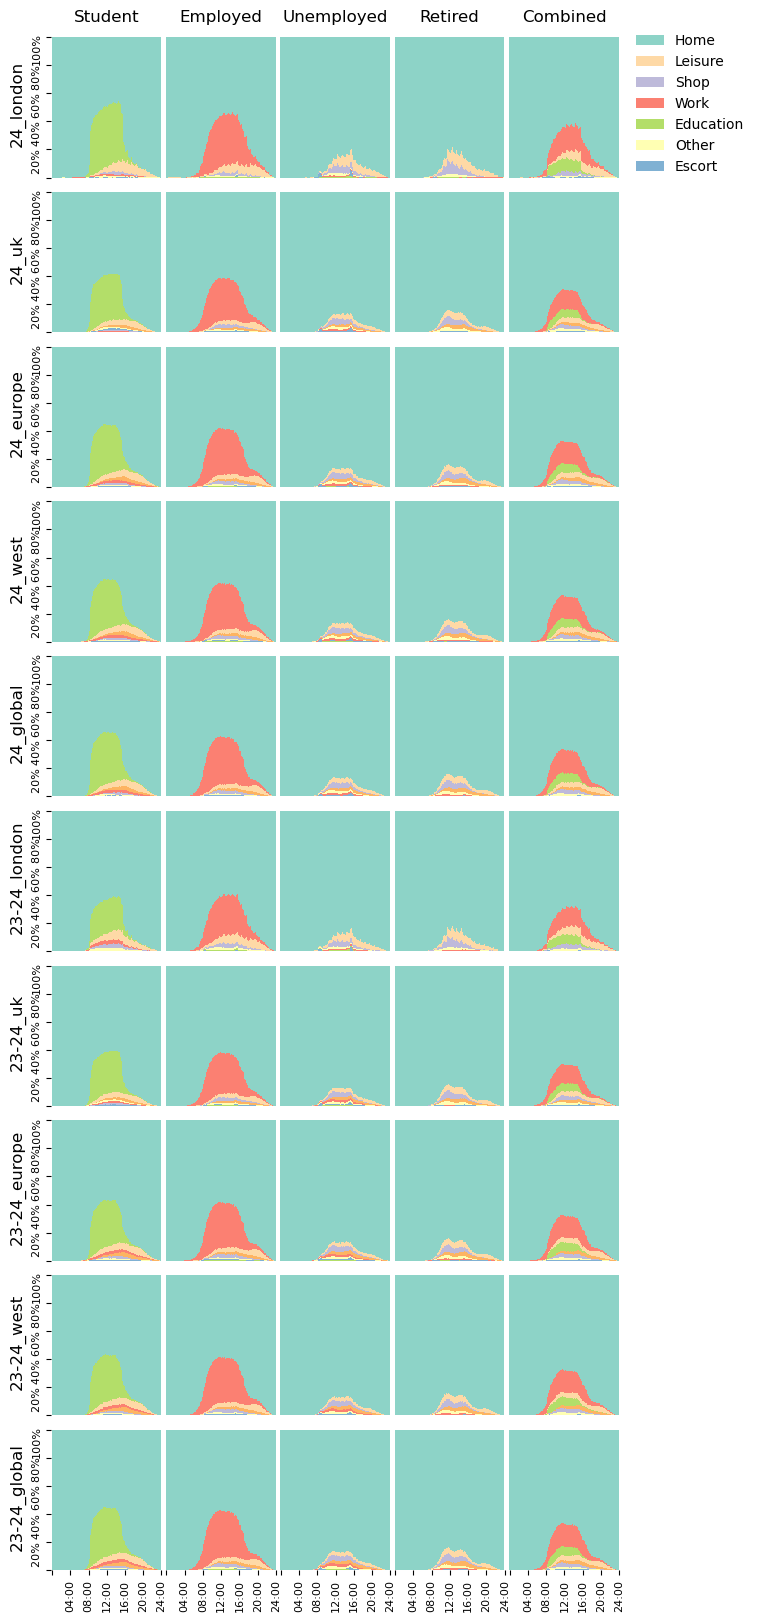

In [8]:
freq_plotter(target_schedules, training_schedules, training_attributes)

In [9]:
for i in training_attributes["23-24_global"].columns:
    print(i)

hid
pid
age
hh_size
hh_income
sex
dwelling
ownership
vehicles
disability
education
can_wfh
occupation
race
has_licence
relationship
employment
employed_type
country
source
year
month
day
hh_zone
weight
access_egress_distance
max_temp_c
rain
avg_speed


In [10]:
training_data_route = Path("../../tmp/foundation/experiment")
all_schedules = pd.read_csv(training_data_route / "00-24_global_activities.csv")
all_attributes = pd.read_csv(
    training_data_route / "00-24_global_attributes.csv"
)

/tmp/ipykernel_1673864/1487252258.py:3: DtypeWarning: Columns (27) have mixed types. Specify dtype option on import or set low_memory=False.
  all_attributes = pd.read_csv(


In [12]:
outpath = Path("../../logs/foundations/experiment")
domains = pd.read_csv(outpath / "eval" / "domains" / "distances.csv").set_index(
    "domain"
)
cols = domains.columns
cols = ["24_london"] + [c for c in cols]

domains = domains[cols]
domains

,24_london,24_london,24_uk,24_europe,24_west,24_global,23-24_london,23-24_uk,23-24_europe,23-24_west,...,10-24_london,10-24_uk,10-24_europe,10-24_west,10-24_global,00-24_london,00-24_uk,00-24_europe,00-24_west,00-24_global
domain,,,,,,,,,,,,,,,,,,,,,
creativity,0.168985,0.168985,0.186441,0.176932,0.176932,0.183629,0.175874,0.176244,0.168724,0.181451,...,0.168502,0.181275,0.176170,0.184710,0.169325,0.168502,0.210462,0.170176,0.172798,0.173297
feasibility,0.001660,0.001660,0.008079,0.011399,0.011399,0.006917,0.006640,0.006474,0.006253,0.007083,...,0.009186,0.003486,0.007249,0.005755,0.006474,0.009186,0.004206,0.009352,0.004427,0.005312
participations,0.086634,0.086634,0.082019,0.065296,0.065296,0.075491,0.085653,0.061316,0.056286,0.076105,...,0.061703,0.069362,0.075416,0.071800,0.067562,0.061703,0.103264,0.070797,0.060170,0.064743
timing,0.086268,0.086268,0.041395,0.040528,0.040528,0.038447,0.078194,0.042951,0.036938,0.061530,...,0.049474,0.037256,0.033190,0.034157,0.032016,0.049474,0.043877,0.036972,0.035320,0.040973
transitions,0.022067,0.022067,0.009293,0.008281,0.008281,0.008834,0.021149,0.007908,0.007086,0.009366,...,0.009775,0.008573,0.008341,0.007392,0.008350,0.009775,0.008289,0.009563,0.008879,0.009841


In [13]:
baseline = domains.iloc[:, 0]
baseline

domain
creativity        0.168985
feasibility       0.001660
participations    0.086634
timing            0.086268
transitions       0.022067
Name: 24_london, dtype: float64

In [14]:
# drop the first column and keep the rest
relative = domains.iloc[:, 1:]

# subtract the baseline column from all columns to get distances
relative = relative.sub(baseline, axis=0)

# # divide each column by the first column to get relative distances
relative = relative.div(baseline, axis=0)

sum_relative = relative.sum(axis=0)
sum_relative

24_london       0.000000
24_uk           2.817685
24_europe       4.512469
24_west         4.512469
24_global       1.970697
23-24_london    2.894235
23-24_uk        1.506970
23-24_europe    1.164103
23-24_west      2.356608
23-24_global    4.500915
20-24_london    9.647945
20-24_uk        1.918489
20-24_europe    4.184238
20-24_west      1.160527
20-24_global    0.872832
10-24_london    3.259184
10-24_uk       -0.206293
10-24_europe    2.042439
10-24_west      1.119404
10-24_global    1.431417
00-24_london    3.259184
00-24_uk        0.854977
00-24_europe    3.319501
00-24_west      0.195528
00-24_global    0.893733
dtype: float64

In [15]:
def unpack_scores(data: pd.Series) -> pd.DataFrame:
    scores = defaultdict(list)
    for yrs in ["24", "23-24", "20-24", "10-24", "00-24"]:
        for scope in ["london", "uk", "europe", "west", "global"]:
            score = data[f"{yrs}_{scope}"]
            scores[yrs].append(score)
    scores = pd.DataFrame(
        scores, index=["london", "uk", "europe", "west", "global"]
    ).T
    return scores


unpack_scores(sum_relative)

,london,uk,europe,west,global
24,0.000000,2.817685,4.512469,4.512469,1.970697
23-24,2.894235,1.506970,1.164103,2.356608,4.500915
20-24,9.647945,1.918489,4.184238,1.160527,0.872832
10-24,3.259184,-0.206293,2.042439,1.119404,1.431417
00-24,3.259184,0.854977,3.319501,0.195528,0.893733


In [16]:
relative.loc["creativity"]

24_london       0.000000
24_uk           0.103303
24_europe       0.047032
24_west         0.047032
24_global       0.086661
23-24_london    0.040768
23-24_uk        0.042960
23-24_europe   -0.001542
23-24_west      0.073776
23-24_global   -0.006876
20-24_london    0.102669
20-24_uk        0.090117
20-24_europe    0.214952
20-24_west      0.045801
20-24_global    0.012991
10-24_london   -0.002857
10-24_uk        0.072729
10-24_europe    0.042523
10-24_west      0.093057
10-24_global    0.002017
00-24_london   -0.002857
00-24_uk        0.245452
00-24_europe    0.007053
00-24_west      0.022569
00-24_global    0.025522
Name: creativity, dtype: float64

In [ ]:
domain_scores = defaultdict(list)

for domain in domains.index:
    domain_scores[domain] = unpack_scores(relative.loc[domain])


def styler(df, vmin=-1, vmax=1):

    df = -df
    df.loc["24", "london"] = None
    df.loc["00-24", "london"] = None
    for yrs in ["24"]:
        for source in ["west", "global"]:
            df.loc[yrs, source] = None
    df.columns = [
        " London  ",
        "   +UK   ",
        " +Europe ",
        "+Western ",
        " +Global ",
    ]
    df.index = ["2024", "+2023", "+2020-22", "+2010-19", "+2000-09"]
    styled = (
        df.style.background_gradient(cmap="RdYlGn", vmin=vmin, vmax=vmax)
        .format("{:.0%}", na_rep="")
        .highlight_null("lightgrey")
        .highlight_null("white", subset=pd.IndexSlice["2024", " London  "])
        .set_table_styles(
            [
                {
                    "selector": "th, td",
                    "props": [
                        ("width", "75px"),
                        # ("min-width", "80px"),
                        # ("max-width", "80px"),
                        ("text-align", "center"),
                    ],
                },
                {
                    "selector": ".row_heading, .index_name",
                    "props": [("font-weight", "bold")],
                },
            ]
        )
    )

    return styled


styler(domain_scores["creativity"])

,London,+UK,+Europe,+Western,+Global
2024,,-10%,-5%,,
+2023,-4%,-4%,0%,-7%,1%
+2020-22,-10%,-9%,-21%,-5%,-1%
+2010-19,0%,-7%,-4%,-9%,-0%
+2000-09,,-25%,-1%,-2%,-3%


In [49]:
styler(domain_scores["feasibility"], vmin=-10, vmax=10)

,London,+UK,+Europe,+Western,+Global
2024,,-387%,-587%,,
+2023,-300%,-290%,-277%,-327%,-603%
+2020-22,-1050%,-300%,-500%,-263%,-243%
+2010-19,-453%,-110%,-337%,-247%,-290%
+2000-09,,-153%,-463%,-167%,-220%


In [51]:
styler(domain_scores["participations"], vmin=-1, vmax=1)

,London,+UK,+Europe,+Western,+Global
2024,,5%,25%,,
+2023,1%,29%,35%,12%,29%
+2020-22,8%,7%,-16%,27%,33%
+2010-19,29%,20%,13%,17%,22%
+2000-09,,-19%,18%,31%,25%


In [52]:
styler(domain_scores["transitions"], vmin=-1, vmax=1)

,London,+UK,+Europe,+Western,+Global
2024,,58%,62%,,
+2023,4%,64%,68%,58%,65%
+2020-22,49%,58%,68%,66%,65%
+2010-19,56%,61%,62%,67%,62%
+2000-09,,62%,57%,60%,55%


In [53]:
styler(domain_scores["timing"], vmin=-1, vmax=1)

,London,+UK,+Europe,+Western,+Global
2024,,52%,53%,,
+2023,9%,50%,57%,29%,59%
+2020-22,38%,52%,51%,59%,60%
+2010-19,43%,57%,62%,60%,63%
+2000-09,,49%,57%,59%,53%


In [55]:
styler(
    (
        domain_scores["participations"]
        + domain_scores["transitions"]
        + domain_scores["timing"]
    )
    / 3,
    vmin=-1,
    vmax=1,
)

,London,+UK,+Europe,+Western,+Global
2024,,38%,47%,,
+2023,5%,48%,53%,33%,51%
+2020-22,32%,39%,34%,51%,52%
+2010-19,42%,46%,46%,48%,49%
+2000-09,,31%,44%,50%,44%


In [ ]:
data_route = Path("../../logs/foundations/experiment")
batch_paths = {}
for yrs in ["24", "23-24", "20-24", "10-24"]:
    for scope in ["london", "uk", "europe", "west", "global"]:
        name = f"{yrs}_{scope}"
        # if name in ["00-24_west", "00-24_global"]:
        #     continue
        batch_paths[name] = data_route / name

schedules = {
    n: pd.read_csv(latest(p)[1] / "synthetic_schedules.csv")
    for n, p in batch_paths.items()
}
attributes = {
    n: load_attributes(latest(p)[1], default=target_attributes)
    for n, p in batch_paths.items()
}

Found versions for 24_london: ['version_0']. Returning ../../logs/foundations/experiment/24_london/version_0
Found versions for 24_uk: ['version_0']. Returning ../../logs/foundations/experiment/24_uk/version_0
Found versions for 24_europe: ['version_0']. Returning ../../logs/foundations/experiment/24_europe/version_0
Found versions for 24_west: ['version_0']. Returning ../../logs/foundations/experiment/24_west/version_0
Found versions for 24_global: ['version_0']. Returning ../../logs/foundations/experiment/24_global/version_0
Found versions for 23-24_london: ['version_0']. Returning ../../logs/foundations/experiment/23-24_london/version_0
Found versions for 23-24_uk: ['version_0']. Returning ../../logs/foundations/experiment/23-24_uk/version_0
Found versions for 23-24_europe: ['version_0']. Returning ../../logs/foundations/experiment/23-24_europe/version_0
Found versions for 23-24_west: ['version_0']. Returning ../../logs/foundations/experiment/23-24_west/version_0
Found versions for 

Class map: {'home': 0, 'shop': 1, 'leisure': 2, 'work': 3, 'other': 4, 'education': 5, 'escort': 6, 'visit': 7}


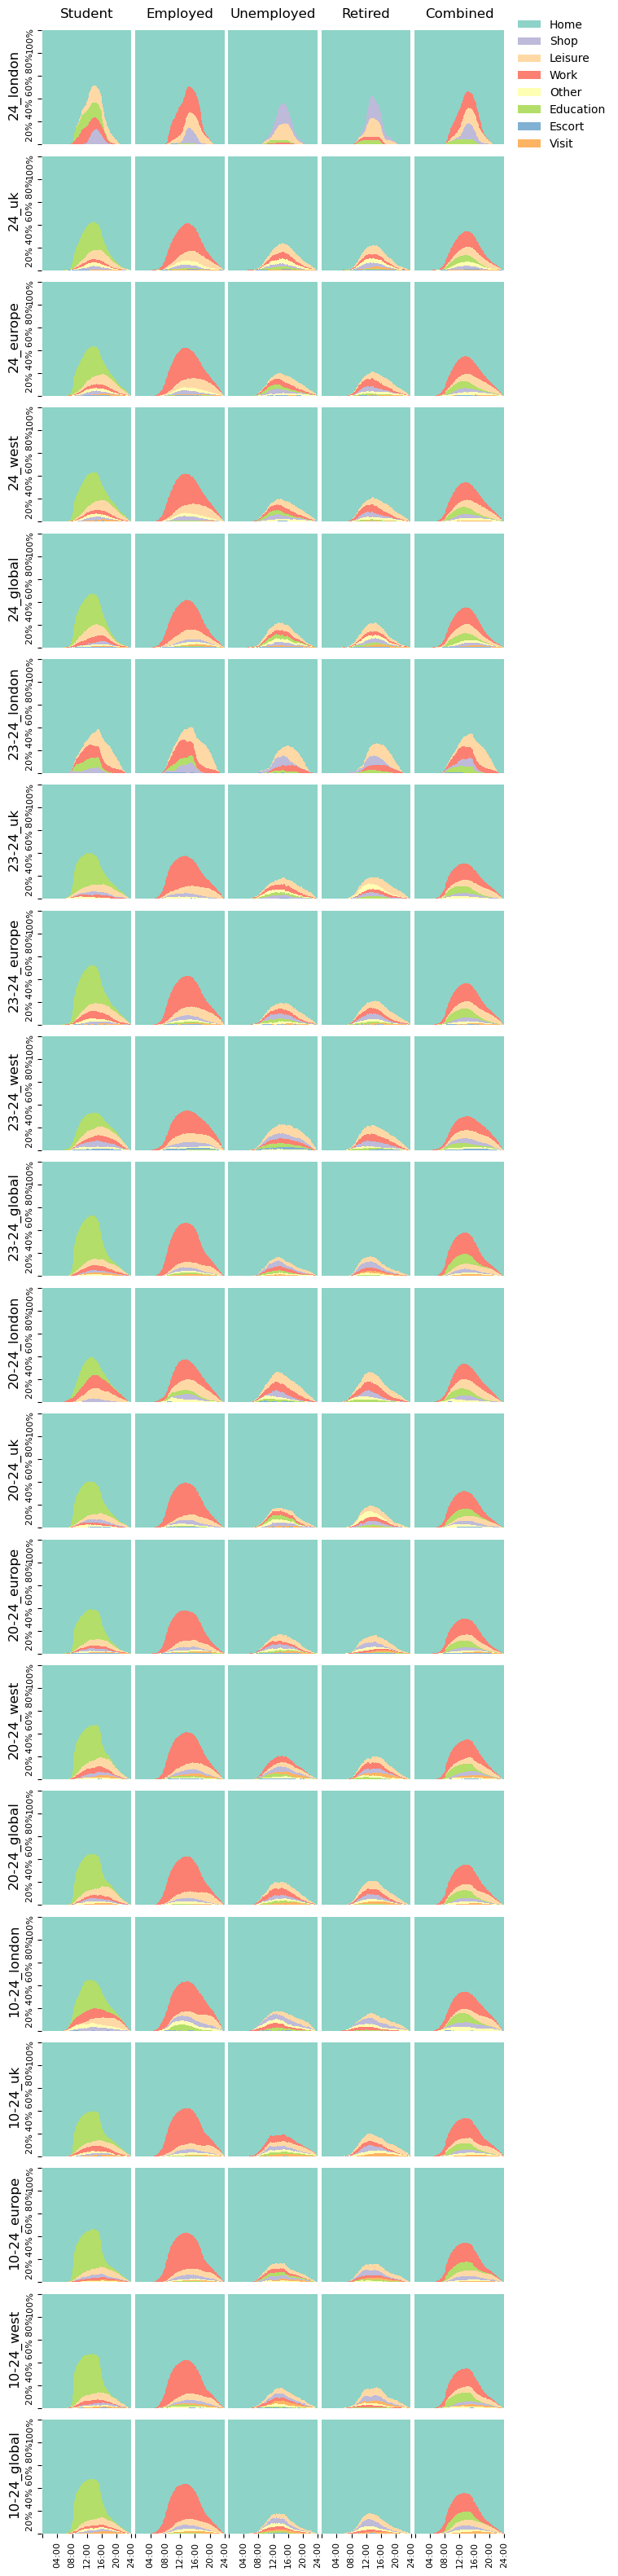

In [ ]:
act_order = schedules["10-24_europe"].act.value_counts().index.to_list()
class_map = {n: i for i, n in enumerate(act_order)}
print(f"Class map: {class_map}")

FILTER = ["student", "employed", "unemployed", "retired"]
NAMES = ["Student", "Employed", "Unemployed", "Retired"]

h = len(schedules)
w = len(FILTER)
fig, axes = plt.subplots(
    h, w + 2, figsize=(w * 2.2, h * 2), sharex=False, sharey=False
)

for i, (name, scheds) in enumerate(schedules.items()):

    splits = split_on(scheds, attributes[name], by="employment")

    for j, f in enumerate(FILTER):
        axes[0, j].set_title(NAMES[j], fontsize=12)
        selected = splits[f]
        ax = plot_agg_acts(
            "",
            selected,
            class_map=class_map,
            ax=axes[i, j],
            legend=False,
            color=cmap,
        )
        ax.set_title(None)
        ax.set_ylabel(None)
        ax.set_xlabel(None)
        ax.set_yticks([])
        ax.set_xticks([])

        axes[-1, j].set_xticks(
            [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
            labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
            rotation=90,
            fontsize=8,
        )

    axes[0, -2].set_title("Combined", fontsize=12)
    ax = plot_agg_acts(
        "",
        scheds,
        class_map=class_map,
        ax=axes[i, -2],
        legend=False,
        color=cmap,
    )
    ax.set_title(None)
    ax.set_ylabel(None)
    ax.set_xlabel(None)
    ax.set_yticks([])
    ax.set_xticks([])

    axes[-1, -2].set_xticks(
        [i / 10 for i in [0, 240, 480, 720, 960, 1200, 1440]],
        labels=["", "04:00", "08:00", "12:00", "16:00", "20:00", "24:00"],
        rotation=90,
        fontsize=8,
    )

    axes[i, 0].set_ylabel(name, fontsize=12)
    axes[i, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    axes[i, 0].set_yticklabels(
        ["", "20% ", "40% ", "60% ", "80% ", "100%"], rotation=90, fontsize=8
    )

    axes[i, -1].axis("off")

elements = [Patch(facecolor=cmap[act], label=act.title()) for act in act_order]
axes[0, -1].axis("off")
axes[0, -1].legend(handles=elements, loc="center left", frameon=False)

plt.subplots_adjust(wspace=0.04, hspace=0.05)